# 5장 2강: 부스팅 계열 모델의 원리와 발전

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 부스팅 계열 모델의 순차 학습 원리와 주요 모델의 차이를 확인합니다.

- AdaBoost와 Gradient Boosting의 순차 학습 원리를 이해합니다.
- Gradient Boosting이 이전 모델의 잔차를 보완하는 흐름을 확인합니다.
- XGBoost와 LightGBM을 같은 데이터에서 비교합니다.
- `learning_rate`, `n_estimators`, `max_depth`의 역할을 확인합니다.
- Early Stopping의 목적을 이해합니다.
- 부스팅이 단계적으로 편향을 줄여가는 이유를 설명합니다.

> 이 실습에서는 5장 2강 교안에서 다룬 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- scikit-learn
- xgboost
- lightgbm
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택의 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

### 사용할 특성

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `2ndFlrSF`
- `FullBath`
- `TotRmsAbvGrd`
- `YearBuilt`
- `YearRemodAdd`
- `Fireplaces`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 숫자형 특성과 `SalePrice`를 선택합니다.
3. Train / Test 데이터로 분리합니다.
4. 같은 데이터에서 Gradient Boosting, XGBoost, LightGBM을 비교합니다.

In [1]:
import time

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

Train 크기: (1168, 12)
Test 크기: (292, 12)

[결측치]


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
GarageArea,0
TotalBsmtSF,0
1stFlrSF,0
2ndFlrSF,0
FullBath,0
TotRmsAbvGrd,0
YearBuilt,0


---

# 필수 1. 부스팅의 순차 학습 원리 확인

## 문제 1. AdaBoost와 Gradient Boosting의 차이를 정리하세요.

### 요구사항

다음 두 모델이 이전 모델의 실수를 어떻게 보완하는지 각각 작성합니다.

- AdaBoost
- Gradient Boosting

### 확인 포인트

- AdaBoost는 틀린 샘플에 더 큰 가중치를 주는가?
- Gradient Boosting은 이전 모델의 잔차를 다음 모델이 학습하는가?

### Q1. AdaBoost와 Gradient Boosting은 각각 무엇에 집중하여 다음 모델을 학습하나요?

**답변:**  
AdaBoost는 이전 모델에서 오차가 큰 샘플에 더 큰 가중치를 주어 다음 모델이 집중하도록 합니다. Gradient Boosting은 손실의 음의 기울기를 다음 모델이 학습하며, 제곱오차 회귀에서는 이것이 현재 예측의 잔차입니다.

## 문제 2. Gradient Boosting의 단계별 성능 변화를 확인하세요.

### 요구사항

1. `GradientBoostingRegressor`를 사용합니다.
2. `n_estimators=100`
3. `learning_rate=0.05`
4. `max_depth=2`
5. `random_state=42`
6. 모델을 학습합니다.
7. `staged_predict()`를 사용해 나무가 추가될 때마다 Test RMSE를 계산합니다.
8. 나무 개수에 따른 Test RMSE를 선 그래프로 나타냅니다.

### 확인 포인트

- 순차적으로 나무가 추가되면서 예측 오차가 감소하는 구간을 확인했는가?
- 이전까지 설명하지 못한 부분을 다음 나무가 보완한다는 개념과 연결할 수 있는가?

,trees,test_rmse
0,1,85132.584919
9,10,67848.160667
49,50,39238.157726
99,100,32559.186347


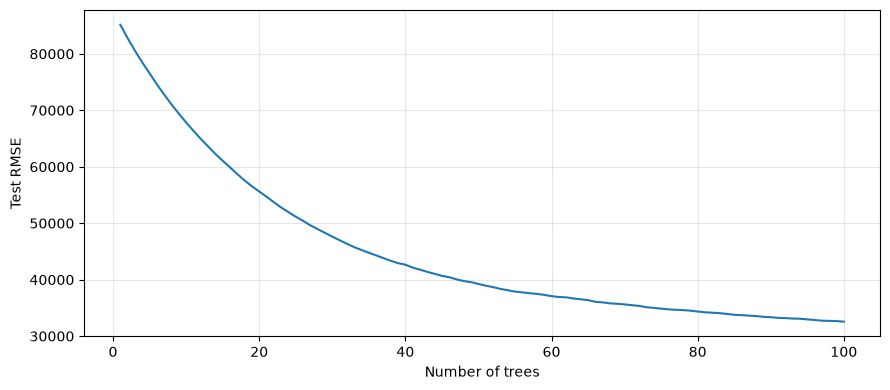

Test 곡선은 지정된 모델의 학습 흐름을 관찰하는 용도이며 최적 나무 수 선택에는 사용하지 않습니다.


In [2]:
import numpy as np
gb_model = GradientBoostingRegressor(n_estimators=100,learning_rate=.05,max_depth=2,random_state=42)
gb_model.fit(X_train,y_train)
stage_rmse = [np.sqrt(mean_squared_error(y_test,prediction)) for prediction in gb_model.staged_predict(X_test)]
stage_df = pd.DataFrame({'trees':range(1,101),'test_rmse':stage_rmse})
display(stage_df.iloc[[0,9,49,99]])
plt.figure(figsize=(9,4)); plt.plot(stage_df['trees'],stage_df['test_rmse'])
plt.xlabel('Number of trees'); plt.ylabel('Test RMSE'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print('Test 곡선은 지정된 모델의 학습 흐름을 관찰하는 용도이며 최적 나무 수 선택에는 사용하지 않습니다.')

### Q2. 부스팅에서 나무를 순차적으로 추가하는 이유는 무엇인가요?

**답변:**  
이전까지 설명하지 못한 오차를 다음 나무가 보완해 전체 예측을 개선하기 위해서입니다.

---

# 필수 2. XGBoost와 LightGBM 비교

## 문제 1. 두 모델을 같은 조건에서 학습하세요.

### 요구사항

다음 공통 설정을 사용합니다.

- `n_estimators=200`
- `learning_rate=0.05`
- `max_depth=3`
- `random_state=42`

다음 두 모델을 학습합니다.

- `XGBRegressor`
- `LGBMRegressor`

각 모델에 대해 다음을 확인합니다.

1. 학습 시간
2. Test RMSE

### 확인 포인트

- XGBoost와 LightGBM을 같은 데이터와 같은 주요 하이퍼파라미터 조건에서 비교했는가?
- LightGBM이 빠른 학습을 강점으로 갖는다는 교안 내용과 연결할 수 있는가?

In [3]:
boost_models = {
 'XGBoost':XGBRegressor(n_estimators=200,learning_rate=.05,max_depth=3,random_state=42,n_jobs=1),
 'LightGBM':LGBMRegressor(n_estimators=200,learning_rate=.05,max_depth=3,random_state=42,n_jobs=1,verbosity=-1)}
boost_rows = []
for name,model in boost_models.items():
    start = time.perf_counter(); model.fit(X_train,y_train); seconds = time.perf_counter()-start
    boost_rows.append({'model':name,'fit_seconds':seconds,'test_rmse':np.sqrt(mean_squared_error(y_test,model.predict(X_test)))})
boost_comparison = pd.DataFrame(boost_rows)
display(boost_comparison)
print('한 번의 소규모 데이터 측정만으로 일반적인 속도 우열을 단정하지 않습니다.')

한 번의 소규모 데이터 측정만으로 일반적인 속도 우열을 단정하지 않습니다.


,model,fit_seconds,test_rmse
0,XGBoost,0.092733,28405.320065
1,LightGBM,0.052519,31813.091613


### Q3. XGBoost와 LightGBM의 기본 트리 성장 방식 차이는 무엇인가요?

**답변:**  
XGBoost의 기본 depthwise 성장 방식은 같은 깊이의 노드를 우선 확장하고, LightGBM은 손실 감소가 가장 큰 잎을 먼저 확장하는 leaf-wise 방식입니다. XGBoost도 lossguide로 다른 정책을 사용할 수 있으며, LightGBM의 깊이·잎 수 제한은 과적합 제어에 중요합니다.

### Q4. CatBoost의 구조적 특징과 강점은 무엇인가요?

**답변:**  
CatBoost는 기본적으로 같은 깊이에서 동일한 분할 조건을 쓰는 대칭 트리와 순서를 활용하는 학습·범주형 통계 처리에 강점이 있습니다. 범주형 특성을 별도 대규모 원핫 인코딩 없이 다룰 수 있고 타깃 통계의 누수·예측 편향을 줄이는 구조를 제공합니다. 어떤 데이터에서도 최상위 성능을 보장하지는 않습니다.

## 문제 2. learning_rate와 n_estimators의 관계를 확인하세요.

### 요구사항

다음 조합을 비교합니다.

```python
settings = [
    {"learning_rate": 0.1, "n_estimators": 50},
    {"learning_rate": 0.05, "n_estimators": 100},
    {"learning_rate": 0.01, "n_estimators": 300}
]
```

각 조합에 대해 `GradientBoostingRegressor(max_depth=2, random_state=42)`를 학습하고 다음을 확인합니다.

1. Test RMSE
2. 학습 시간

### 확인 포인트

- learning_rate가 작을수록 더 많은 나무가 필요할 수 있음을 확인했는가?
- 성능뿐 아니라 학습 시간도 함께 확인했는가?

In [3]:
settings = [{'learning_rate':.1,'n_estimators':50},{'learning_rate':.05,'n_estimators':100},{'learning_rate':.01,'n_estimators':300}]
setting_rows = []
for setting in settings:
    model = GradientBoostingRegressor(max_depth=2,random_state=42,**setting)
    start = time.perf_counter(); model.fit(X_train,y_train); seconds = time.perf_counter()-start
    setting_rows.append({**setting,'fit_seconds':seconds,'test_rmse':np.sqrt(mean_squared_error(y_test,model.predict(X_test)))})
settings_df = pd.DataFrame(setting_rows); display(settings_df)

,learning_rate,n_estimators,fit_seconds,test_rmse
0,0.10,50,0.045831,31791.283180
1,0.05,100,0.082683,32559.186347
2,0.01,300,0.239548,37165.991330


### Q5. learning_rate를 작게 만들면 왜 n_estimators를 함께 늘려야 할 수 있나요?

**답변:**  
learning_rate는 새 나무의 예측에 곱하는 보정 폭입니다. 작으면 한 단계의 개선이 작아져 충분히 학습하려면 더 많은 나무가 필요할 수 있습니다. 학습 시간과 과적합 위험까지 함께 검증해야 하며 두 값의 곱만 같다고 동일한 모델이 되지는 않습니다.

---

# 과제 1. Early Stopping과 부스팅 모델 선택

## 배경

교안에서는 `n_estimators`를 충분히 크게 설정하고, 검증 성능이 더 이상 좋아지지 않으면 학습을 멈추는 **Early Stopping**을 소개했습니다.

이번 과제에서는 XGBoost에서 이 흐름을 적용합니다.

> 과제는 필수 실습에서 사용한 모델과 하이퍼파라미터를 그대로 활용하는 수준입니다.

## 요구사항

1. Train 데이터를 다시 Train / Validation으로 나눕니다.
2. `XGBRegressor`를 사용합니다.
3. `n_estimators=1000`
4. `learning_rate=0.05`
5. `max_depth=3`
6. `early_stopping_rounds=20`
7. Train 데이터로 학습하고 Validation 데이터를 `eval_set`으로 전달합니다.
8. Test 데이터의 RMSE를 계산합니다.
9. 실제로 사용된 나무 수를 확인합니다.
10. `n_estimators=1000`을 모두 사용하지 않고 중간에 멈췄다면 그 이유를 설명합니다.

11. Q7에서 배깅·랜덤포레스트·부스팅의 작동 원리와 편향·분산, 과적합에 미치는 영향을 비교합니다. 새로운 모델 학습 코드는 요구하지 않습니다.

### 확인 포인트

- Early Stopping이 Validation 성능을 기준으로 동작한다는 점을 이해했는가?
- 불필요하게 많은 나무를 쌓는 것을 막는 목적을 설명할 수 있는가?
- 과적합 방지와 학습 시간 절약이라는 두 가지 의미를 설명할 수 있는가?
- 배깅의 부트스트랩·예측 결합, 랜덤포레스트의 특성 무작위 선택, 부스팅의 순차적 오류 보완을 설명할 수 있는가?
- 각 방식이 편향·분산에 미치는 일반적인 영향과 과적합 가능성을 구분할 수 있는가?


In [5]:
X_sub,X_valid,y_sub,y_valid = train_test_split(X_train,y_train,test_size=.2,random_state=42)
early_model = XGBRegressor(n_estimators=1000,learning_rate=.05,max_depth=3,early_stopping_rounds=20,
    eval_metric='rmse',random_state=42,n_jobs=1)
early_model.fit(X_sub,y_sub,eval_set=[(X_valid,y_valid)],verbose=False)
early_test_rmse = np.sqrt(mean_squared_error(y_test,early_model.predict(X_test)))
best_tree_count = early_model.best_iteration+1
trained_tree_count = early_model.get_booster().num_boosted_rounds()
print('선택된 예측 나무 수:',best_tree_count)
print('실제로 학습한 나무 수(대기 구간 포함):',trained_tree_count)
print('Test RMSE:',early_test_rmse)
print('best_iteration은 0부터 시작합니다. predict는 최적 반복까지 사용하며, 학습된 나무 수에는 이후 대기 구간이 포함될 수 있습니다.')

선택된 예측 나무 수: 108
실제로 학습한 나무 수(대기 구간 포함): 128
Test RMSE: 30332.878531389004
best_iteration은 0부터 시작합니다. predict는 최적 반복까지 사용하며, 학습된 나무 수에는 이후 대기 구간이 포함될 수 있습니다.


### Q6. Early Stopping은 어떤 상황에서 학습을 멈추나요?

**답변:**  
Validation 지표가 설정한 대기 횟수 동안 개선되지 않으면 멈춥니다. 이번 최적 반복은 0부터 세어 107이고 예측에 사용하는 나무는 108개입니다. 실제 학습한 나무는 128개로, 최적 반복 이후 20회의 대기 구간이 포함됩니다. 최대 1,000회 전에 멈춘 것은 그 구간에서 Validation RMSE가 더 좋아지지 않았기 때문이며, Test RMSE는 30,332.88입니다.

### Q7. 배깅·랜덤포레스트·부스팅의 작동 원리와 편향·분산에 미치는 영향을 비교하세요.

다음 항목을 포함하여 각 방법을 설명하세요.

1. **배깅:** 부트스트랩 표본을 만드는 방법과 여러 모델의 예측을 결합하는 방법, 분산 감소의 이유
2. **랜덤포레스트:** 배깅에 더해 각 노드의 분할 후보 특성을 무작위로 선택하는 이유와 트리 간 상관·분산에 미치는 영향
3. **부스팅:** 이전 모델의 오류를 순차적으로 보완하는 원리와 편향 감소의 관계, 과적합 가능성 및 이를 줄이는 방법

> 편향·분산에 대한 효과는 일반적인 경향입니다. 한 방법이 편향 또는 분산만 바꾸거나 과적합을 항상 막는다고 단정하지 마세요.

**답변:**

- 배깅: 원본에서 복원추출한 표본마다 모델을 독립적으로 학습하고 회귀 예측을 평균냅니다. 서로 다른 오차가 일부 상쇄되어 특히 고분산 모델의 분산을 낮추지만 공통 오차·편향은 남을 수 있습니다.
- 랜덤포레스트: 부트스트랩과 평균화에 더해 각 분기의 후보 특성을 무작위로 제한하여 강한 특성이 모든 나무를 지배하는 것을 줄입니다. 트리 간 상관을 낮추면 평균 예측의 분산을 더 줄일 수 있지만 개별 트리의 편향이 커질 수도 있습니다. 회귀 모델은 기본 max_features=1.0이므로 특성 제한 효과를 원하면 값을 명시해야 합니다.
- 부스팅: 이전 앙상블의 오류를 순차적으로 보완하여 표현력을 높이고 편향을 줄이는 데 초점을 둡니다. 너무 많은·깊은 나무는 잡음까지 학습하여 분산과 과적합을 키울 수 있습니다. 낮은 learning_rate, 깊이 제한, 규제, Validation 기반 Early Stopping으로 제어합니다.


---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 부스팅은 여러 모델을 병렬로 학습하나요, 순차적으로 학습하나요?  
-> 모델 추가는 순차적으로 이루어집니다.

2. AdaBoost는 이전 모델이 틀린 샘플을 어떻게 처리하나요?  
-> 오차가 큰 샘플의 가중치를 높입니다.

3. Gradient Boosting은 다음 모델이 무엇을 학습하나요?  
-> 손실의 음의 기울기이며 제곱오차에서는 잔차입니다.

4. XGBoost와 LightGBM의 기본 트리 성장 방식은 어떻게 다른가요?  
-> 기본 depthwise와 leaf-wise입니다.

5. `learning_rate`와 `n_estimators`는 어떤 관계가 있나요?  
-> 작은 학습률은 보통 더 많은 나무를 필요로 합니다.

6. Early Stopping을 사용하는 이유는 무엇인가요?  
-> 검증 개선이 없을 때 불필요한 학습과 과적합을 줄입니다.

7. 부스팅은 편향과 분산 중 어떤 문제를 줄이는 데 특히 초점을 두나요?  
-> 특히 편향 감소에 초점을 두지만 분산도 바뀝니다.